In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import sqlite3
import os
import matplotlib.pyplot as plt
%matplotlib inline


D:\Anaconda\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
symbols = {
    "Nasdaq100": "^NDX",
    "Bist100": "XU100.IS"
}

frames = []

for market, ticker in symbols.items():
    df = yf.download(tickers=ticker,start="2010-01-01", interval="1d", auto_adjust=True, multi_level_index=False)

    df = df.reset_index()

    df["market"] = market
    df["symbol"] = ticker

    frames.append(df)

prices = pd.concat(frames, ignore_index=True)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [3]:
prices[prices["Date"] == "2010-01-04"]

,Date,Close,High,Low,Open,Volume,market,symbol
0,2010-01-04,1886.699951,1890.020020,1881.630005,1882.689941,1931380000,Nasdaq100,^NDX
4208,2010-01-04,533.679199,533.679199,524.098256,528.183195,85197600000,Bist100,XU100.IS


In [4]:
def create_database(database):
    if os.path.exists(database):
        os.remove(database)

    conn = sqlite3.connect(database)
    cursor = conn.cursor()

    return conn, cursor

In [5]:
conn, cursor = create_database("MARKET.db")
prices.to_sql("PRICES", conn, if_exists="replace", index=False)
conn.close()

In [6]:
conn = sqlite3.connect("MARKET.db")

In [7]:
query = '''
SELECT

strftime('%Y', P.Date) AS YEAR,
market AS MARKET,
(MAX(CLOSE)-MIN(CLOSE))/MIN(CLOSE) * 100 AS MAX_GAIN 
FROM PRICES P 
WHERE market IN ('Nasdaq100', 'Bist100') 
GROUP BY strftime('%Y', P.Date), market
HAVING MAX_GAIN > 35



'''

In [8]:
result = pd.read_sql(query, conn)
result

,YEAR,MARKET,MAX_GAIN
0,2010,Bist100,46.787402
1,2011,Bist100,41.212401
2,2012,Bist100,57.672223
3,2013,Bist100,45.853665
4,2014,Bist100,40.930253
5,2017,Bist100,51.467752
6,2018,Bist100,38.674384
7,2019,Bist100,37.142031
8,2019,Nasdaq100,42.803385
9,2020,Bist100,75.663719


In [9]:
query = '''
SELECT

strftime('%Y', P.Date) AS YEAR,
market AS MARKET,
(MAX(CLOSE)-MIN(CLOSE))/MIN(CLOSE) * 100 AS MAX_GAIN 
FROM PRICES P 
WHERE market IN ('Nasdaq100', 'Bist100') 
GROUP BY strftime('%Y', P.Date), market




'''


result = pd.read_sql(query, conn)
result

,YEAR,MARKET,MAX_GAIN
0,2010,Bist100,46.787402
1,2010,Nasdaq100,29.367483
2,2011,Bist100,41.212401
3,2011,Nasdaq100,19.197144
4,2012,Bist100,57.672223
5,2012,Nasdaq100,23.345367
6,2013,Bist100,45.853665
7,2013,Nasdaq100,32.989261
8,2014,Bist100,40.930253
9,2014,Nasdaq100,26.080222


In [10]:
# her bir market için yıllık getiri oranları

query = '''

SELECT
Y.YEAR,
Y.MARKET,
(LAST.Close-FIRST.Close)/FIRST.Close *100 AS ANNUAL_GAIN


FROM 

(
SELECT
strftime('%Y', Date) AS YEAR,
market AS MARKET,
MIN(Date) AS FIRST_DATE,
MAX(Date) AS LAST_DATE
FROM PRICES 
GROUP BY strftime('%Y', Date), market 

) AS Y

JOIN PRICES AS FIRST ON FIRST.Date = Y.FIRST_DATE AND FIRST.market = Y.market
JOIN PRICES AS LAST ON LAST.Date = Y.LAST_DATE AND LAST.market = Y.market


GROUP BY Y.YEAR, Y.MARKET




 



'''




result = pd.read_sql(query, conn)
result


,YEAR,MARKET,ANNUAL_GAIN
0,2010,Bist100,23.677577
1,2010,Nasdaq100,17.552349
2,2011,Bist100,-24.170694
3,2011,Nasdaq100,1.046925
4,2012,Bist100,52.331287
5,2012,Nasdaq100,14.598442
6,2013,Bist100,-14.867012
7,2013,Nasdaq100,30.786065
8,2014,Bist100,27.969060
9,2014,Nasdaq100,18.877410


In [11]:
# her piyasanın en kötü olduğu yıl


query=(

'''
SELECT
YEAR,
MARKET,
MIN(ANNUAL_RETURN)

FROM
(SELECT

Y.YEAR,
Y.MARKET,
(LAST.CLOSE-FIRST.CLOSE)/FIRST.CLOSE AS ANNUAL_RETURN



FROM
(SELECT
strftime('%Y', P.DATE) AS YEAR,
market AS MARKET,
MIN(P.Date) AS FIRST_DATE,
MAX(P.Date) AS LAST_DATE
FROM
PRICES P

GROUP BY strftime('%Y', P.DATE), market
) AS Y

JOIN PRICES AS FIRST
    ON FIRST.DATE = Y.FIRST_DATE
    AND FIRST.MARKET = Y.MARKET

JOIN PRICES AS LAST
    ON LAST.DATE = Y.LAST_DATE
    AND LAST.MARKET = Y.MARKET

GROUP BY Y.YEAR, Y.MARKET
)

GROUP BY MARKET

'''
)
result = pd.read_sql(query, conn)
result

,YEAR,MARKET,MIN(ANNUAL_RETURN)
0,2011,Bist100,-0.241707
1,2022,Nasdaq100,-0.337055


In [12]:
# her markette yıllık aylık için günlük ortalama getiriyi hesapla

query=(
    '''
    
    SELECT
    strftime('%Y', DATE) YEAR,
    strftime('%m', DATE) MONTH,
    MARKET,
    AVG((CLOSE-OPEN)/OPEN) AS AVERAGE_DAILY_RETURN

    
    FROM PRICES P

    GROUP BY strftime('%Y', DATE), strftime('%m', DATE), MARKET
    
    '''
)

AVG_DAILY_DF = pd.read_sql(query, conn)
AVG_DAILY_DF

,YEAR,MONTH,market,AVERAGE_DAILY_RETURN
0,2010,01,Bist100,0.002344
1,2010,01,Nasdaq100,-0.003650
2,2010,02,Bist100,-0.007461
3,2010,02,Nasdaq100,0.002555
4,2010,03,Bist100,0.004235
...,...,...,...,...
397,2026,07,Nasdaq100,-0.002878
398,2026,08,Bist100,0.002124
399,2026,08,Nasdaq100,0.000658
400,2026,09,Bist100,-0.001781


In [13]:
bist_monthly = AVG_DAILY_DF[AVG_DAILY_DF["market"] == "Bist100"]

In [14]:
bist_monthly["Date"] = bist_monthly["YEAR"] + '-' + bist_monthly["MONTH"]

In [15]:
bist_monthly

,YEAR,MONTH,market,AVERAGE_DAILY_RETURN,Date
0,2010,01,Bist100,0.002344,2010-01
2,2010,02,Bist100,-0.007461,2010-02
4,2010,03,Bist100,0.004235,2010-03
6,2010,04,Bist100,0.001196,2010-04
8,2010,05,Bist100,-0.002038,2010-05
...,...,...,...,...,...
392,2026,05,Bist100,-0.003677,2026-05
394,2026,06,Bist100,-0.001801,2026-06
396,2026,07,Bist100,-0.001768,2026-07
398,2026,08,Bist100,0.002124,2026-08


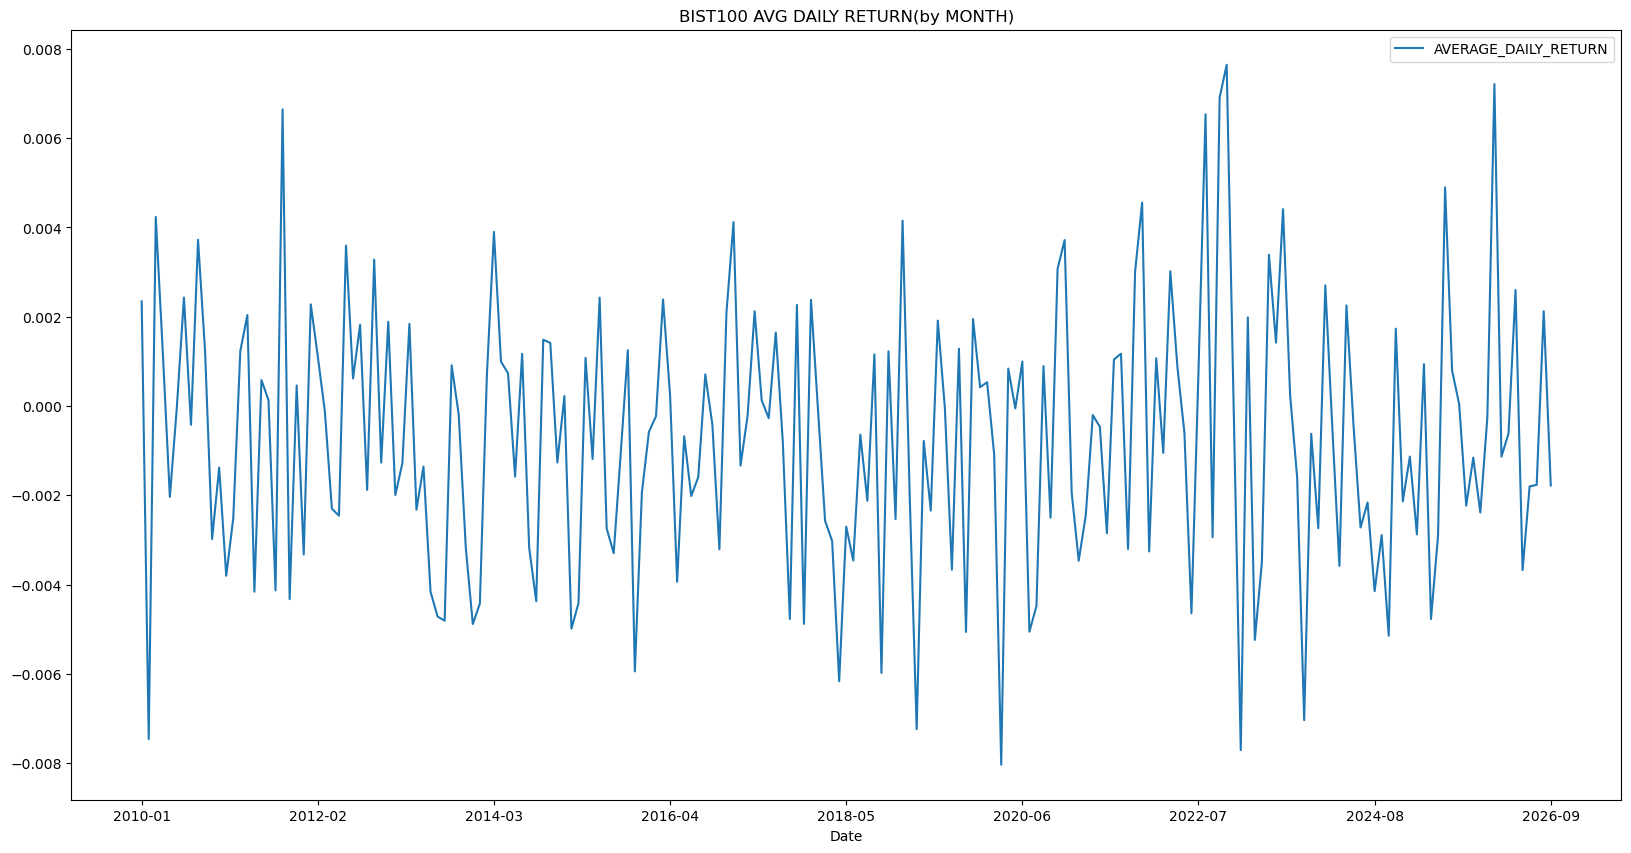

In [16]:

bist_monthly.plot(x="Date", y="AVERAGE_DAILY_RETURN", figsize=(20,10), title="BIST100 AVG DAILY RETURN(by MONTH)")
plt.show()

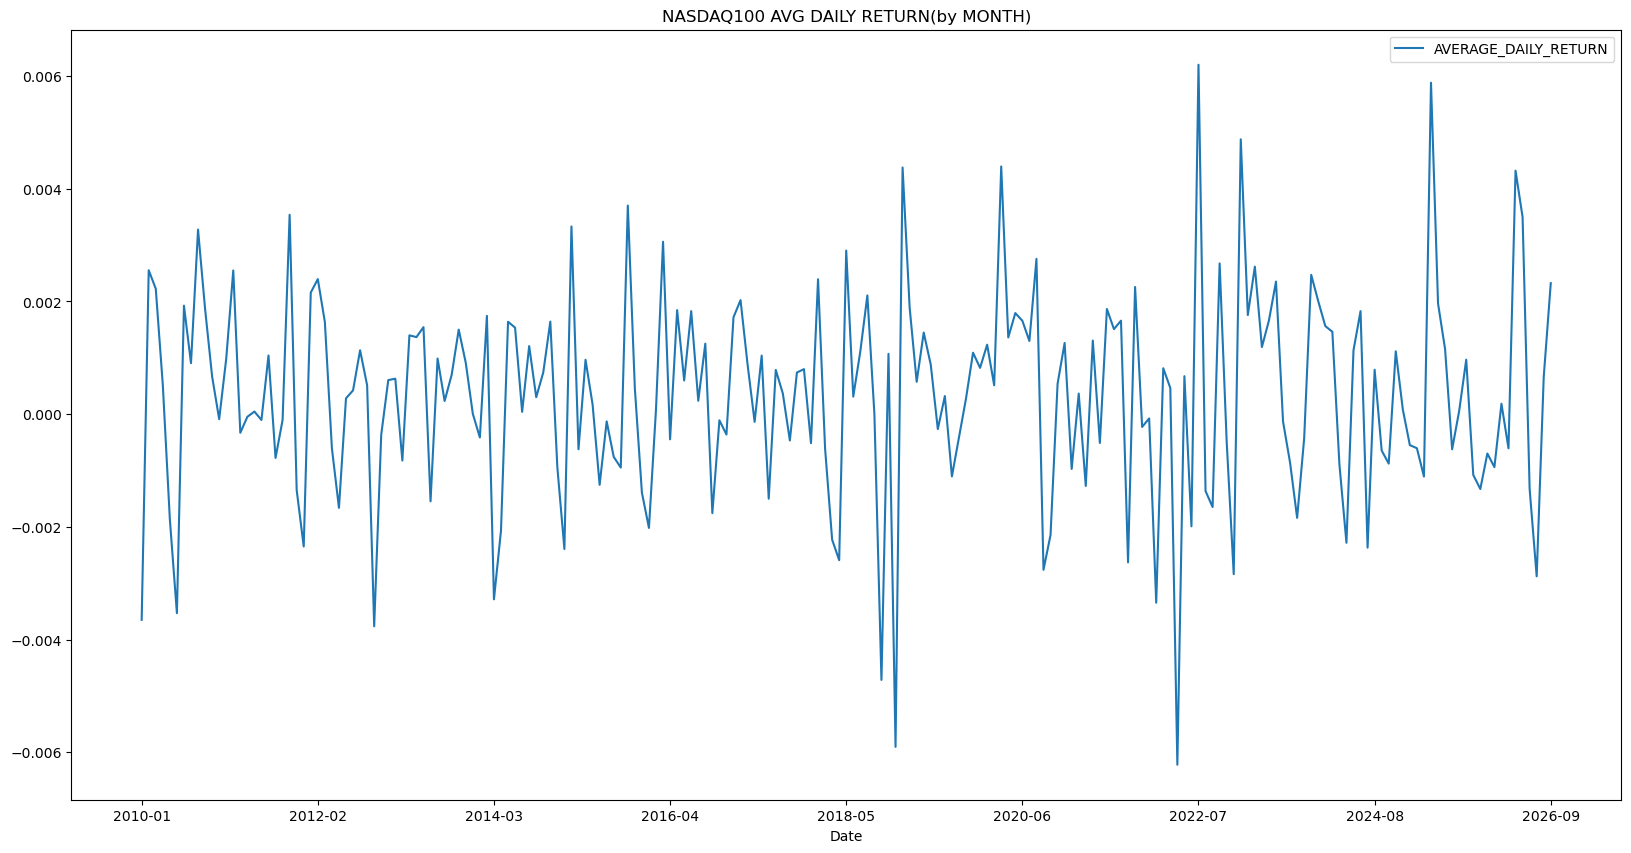

In [17]:
nasdaq_monthly = AVG_DAILY_DF[AVG_DAILY_DF["market"] == "Nasdaq100"]
nasdaq_monthly["Date"] = nasdaq_monthly["YEAR"] + '-' + nasdaq_monthly["MONTH"]
nasdaq_monthly.plot(x="Date", y="AVERAGE_DAILY_RETURN", figsize=(20,10), title="NASDAQ100 AVG DAILY RETURN(by MONTH)")
plt.show()

In [18]:
query = (
    '''

    SELECT
    strftime('%Y', P.DATE) AS YEAR,
    strftime('%m', P.DATE) AS MONTH,
    MARKET,
    AVG((P.CLOSE-P.OPEN)/P.OPEN) AS AVG_DAILY_RETURN,
    COUNT(*) AS TRADING_DAYS
    
    FROM PRICES P
    
    GROUP BY strftime('%Y', DATE), strftime('%m', DATE), MARKET
    HAVING COUNT(P.CLOSE) >= 20 AND AVG_DAILY_RETURN > 0.002


    '''
        
)

result = pd.read_sql(query, conn)
result

,YEAR,MONTH,market,AVG_DAILY_RETURN,TRADING_DAYS
0,2010,01,Bist100,0.002344,20
1,2010,03,Bist100,0.004235,23
2,2010,03,Nasdaq100,0.002227,23
3,2010,07,Bist100,0.002431,22
4,2010,09,Bist100,0.003724,20
5,2010,09,Nasdaq100,0.003276,21
6,2011,04,Bist100,0.002037,21
7,2011,09,Bist100,0.006647,21
8,2011,10,Nasdaq100,0.003539,21
9,2012,01,Bist100,0.002278,22


In [19]:
query = (
    '''
    SELECT
    strftime('%Y', DATE) AS YEAR,
    strftime('%m', DATE) AS MONTH,
    MARKET,
    AVG((HIGH-LOW)/OPEN) AS DAILY_AVG_RANGE,
    COUNT(*) AS TRADING_DAYS
    FROM PRICES P
    WHERE DATE >= '2018-01-01'
    GROUP BY strftime('%Y', DATE), strftime('%m', DATE), MARKET
    HAVING TRADING_DAYS >= 20 AND DAILY_AVG_RANGE > 0.015
    ORDER BY DAILY_AVG_RANGE DESC

    
    '''
)

result = pd.read_sql(query, conn)
result.head(30)

,YEAR,MONTH,market,DAILY_AVG_RANGE,TRADING_DAYS
0,2020,03,Nasdaq100,0.051948,22
1,2021,12,Bist100,0.042050,23
2,2023,01,Bist100,0.040740,22
3,2020,03,Bist100,0.040274,22
4,2025,04,Nasdaq100,0.035717,21
5,2023,05,Bist100,0.034387,21
6,2022,09,Bist100,0.033201,22
7,2023,10,Bist100,0.030616,22
8,2022,05,Nasdaq100,0.030616,21
9,2023,08,Bist100,0.030568,22


In [20]:
query = (
    '''
    SELECT

    MARKET,
    CLASS,
    COUNT(*) AS COUNT_CLASS
    
    FROM
    
    (SELECT

   

    MARKET AS MARKET,
    (CLOSE-OPEN)/OPEN AS DAILY_RETURN,

     CASE
        WHEN (CLOSE-OPEN)/OPEN >= 0.01 
            THEN 'STRONG UP'
        WHEN 0.01 > (CLOSE-OPEN)/OPEN 
            AND  (CLOSE-OPEN)/OPEN > 0 
            THEN 'UP'
        WHEN 0 >= (CLOSE-OPEN)/OPEN 
            AND (CLOSE-OPEN)/OPEN >= -0.01 
            THEN 'DOWN'
        WHEN -0.01 >= (CLOSE-OPEN)/OPEN 
            THEN 'STRONG DOWN'

    END AS CLASS
    
    FROM PRICES

    WHERE DATE >= '2018-01-01'
    ORDER BY DATE

    ) AS SUBQUERY

    GROUP BY MARKET,CLASS
    ORDER BY MARKET,CLASS

    
    '''
)

result = pd.read_sql(query, conn)
result

,MARKET,CLASS,COUNT_CLASS
0,Bist100,DOWN,640
1,Bist100,STRONG DOWN,485
2,Bist100,STRONG UP,419
3,Bist100,UP,635
4,Nasdaq100,DOWN,686
5,Nasdaq100,STRONG DOWN,322
6,Nasdaq100,STRONG UP,347
7,Nasdaq100,UP,840


In [21]:
query = (
    '''

    SELECT
    
    
    
    MARKET AS MARKET,
    COUNT(*) AS TRADING_DAY,

    SUM(CASE
        WHEN CLOSE > OPEN
            THEN 1
        WHEN CLOSE < OPEN
            THEN 0
        END) AS UP_DAYS,

    SUM(CASE
        WHEN CLOSE < OPEN
            THEN 1
        WHEN CLOSE > OPEN
            THEN 0
        END) AS DOWN_DAYS,

    SUM(CASE
        WHEN CLOSE > OPEN
            THEN 1
        WHEN CLOSE < OPEN
            THEN 0
        END) * 1.0 /COUNT(*) AS UP_RATIO

    
    
    
    FROM PRICES P

    WHERE P.DATE >= '2018-01-01'

    GROUP BY MARKET
    
    '''
)

result = pd.read_sql(query, conn)
result


,MARKET,TRADING_DAY,UP_DAYS,DOWN_DAYS,UP_RATIO
0,Bist100,2179,1054,1120,0.483708
1,Nasdaq100,2195,1187,1008,0.540774


In [22]:
query=(
    '''


    SELECT

    
    
    
    MARKET AS MARKET,
    strftime('%Y', DATE) AS YEAR,
    COUNT(*) AS TRADING_DAY,

    SUM(CASE
        WHEN CLOSE > OPEN
            THEN 1
        WHEN CLOSE < OPEN
            THEN 0
        END) AS UP_DAYS,

    SUM(CASE
        WHEN CLOSE < OPEN
            THEN 1
        WHEN CLOSE > OPEN
            THEN 0
        END) AS DOWN_DAYS

    

    
    
    
    FROM PRICES P

    WHERE P.DATE >= '2018-01-01' 

    GROUP BY strftime('%Y', DATE), MARKET
    HAVING UP_DAYS > DOWN_DAYS
    ORDER BY MARKET ASC, YEAR ASC
    
   
    
    '''
)

result = pd.read_sql(query, conn)
result

,MARKET,YEAR,TRADING_DAY,UP_DAYS,DOWN_DAYS
0,Bist100,2020,251,127,123
1,Bist100,2021,248,124,123
2,Bist100,2022,252,141,109
3,Bist100,2026,183,97,86
4,Nasdaq100,2019,252,141,111
5,Nasdaq100,2020,253,149,104
6,Nasdaq100,2021,252,138,114
7,Nasdaq100,2023,250,146,104
8,Nasdaq100,2024,252,135,117
9,Nasdaq100,2025,250,138,112


In [28]:
query=(
    '''
    SELECT
    *
    FROM
    (SELECT

    MARKET AS MARKET,
    DATE,
    VOLUME
    
    FROM PRICES

    WHERE DATE >= '2018-01-01' AND MARKET='Bist100'

    ORDER BY VOLUME DESC
    LIMIT 10
    ) 

    UNION ALL

    SELECT
    *
    
    FROM
    (SELECT

    MARKET AS MARKET,
    DATE,
    VOLUME
    
    FROM PRICES

    WHERE DATE >= '2018-01-01' AND MARKET='Nasdaq100'

    ORDER BY VOLUME DESC
    LIMIT 10
    ) 

    
    '''
    
)

result = pd.read_sql(query, conn)
result

,MARKET,DATE,VOLUME
0,Bist100,2020-07-07 00:00:00,766805850000
1,Bist100,2020-07-08 00:00:00,591750790000
2,Bist100,2020-06-30 00:00:00,539126540000
3,Bist100,2020-07-01 00:00:00,528177730000
4,Bist100,2020-07-09 00:00:00,526519920000
5,Bist100,2020-07-14 00:00:00,517175780000
6,Bist100,2020-07-22 00:00:00,516305390000
7,Bist100,2020-07-10 00:00:00,502818720000
8,Bist100,2020-06-19 00:00:00,489228860000
9,Bist100,2020-07-21 00:00:00,473565610000


In [44]:
# 2018 ve sonrası için her markette, bir önceki güne göre kapanışı %2’den fazla düşen günler


query = (
    '''
    SELECT

    T.DATE,
    T.MARKET,
    (T.CLOSE-T.PREV_CLOSE)/T.PREV_CLOSE AS DAILY_CHANGE

    FROM
   (SELECT
        DATE,
        MARKET,
        CLOSE,
        LAG(CLOSE) OVER (
        PARTITION BY MARKET
        ORDER BY DATE
        ) AS PREV_CLOSE

        FROM PRICES
        WHERE DATE >= '2018-01-01'

    ) AS T

    WHERE (T.CLOSE-T.PREV_CLOSE)/T.PREV_CLOSE < -0.02
    ORDER BY MARKET, DATE
    
    '''
)


result = pd.read_sql(query, conn)
result

,DATE,MARKET,DAILY_CHANGE
0,2018-01-15 00:00:00,Bist100,-0.021679
1,2018-02-20 00:00:00,Bist100,-0.021134
2,2018-04-10 00:00:00,Bist100,-0.021593
3,2018-04-25 00:00:00,Bist100,-0.024144
4,2018-04-30 00:00:00,Bist100,-0.030958
...,...,...,...
310,2026-02-12 00:00:00,Nasdaq100,-0.020382
311,2026-03-26 00:00:00,Nasdaq100,-0.023838
312,2026-06-05 00:00:00,Nasdaq100,-0.047692
313,2026-06-23 00:00:00,Nasdaq100,-0.032946


In [47]:
# 2018 ve sonrası için her markette, bir önceki güne göre kapanışı %2’den fazla düşen günler


query = (
    '''
  
   SELECT
        DATE,
        MARKET,
        CLOSE,
        LAG(CLOSE) OVER (
        PARTITION BY MARKET
        ORDER BY DATE
        ) AS PREV_CLOSE

        FROM PRICES
        WHERE DATE >= '2018-01-01' 
    
    '''
)


result = pd.read_sql(query, conn)
result

,Date,market,Close,PREV_CLOSE
0,2018-01-02 00:00:00,Bist100,1175.235718,NaN
1,2018-01-03 00:00:00,Bist100,1160.515869,1175.235718
2,2018-01-04 00:00:00,Bist100,1154.905884,1160.515869
3,2018-01-05 00:00:00,Bist100,1166.372803,1154.905884
4,2018-01-08 00:00:00,Bist100,1163.038818,1166.372803
...,...,...,...,...
4369,2026-09-21 00:00:00,Nasdaq100,30482.349609,29644.169922
4370,2026-09-22 00:00:00,Nasdaq100,30732.400391,30482.349609
4371,2026-09-23 00:00:00,Nasdaq100,30470.289062,30732.400391
4372,2026-09-24 00:00:00,Nasdaq100,30478.859375,30470.289062


In [61]:
# kendi marketinin 2018 sonrası genel yıllık hacim ortalamasının üzerinde kalan yıllar


query = (
    '''
    WITH A AS(
    SELECT
    strftime('%Y', DATE) AS YEAR,
    MARKET AS MARKET,
    AVG(VOLUME) AS AVG_VOLUME_YEAR
    FROM PRICES

    GROUP BY strftime('%Y', DATE), MARKET
    ORDER BY strftime('%Y', DATE)
    ),


    B AS(
    SELECT
    MARKET,
    AVG(AVG_VOLUME_YEAR) AS AVG_VOLUME_YEARS
    FROM A

    GROUP BY MARKET
    
    )
    
    SELECT

    A.YEAR,
    A.MARKET,
    A.AVG_VOLUME_YEAR,
    B.AVG_VOLUME_YEARS

    FROM A
    JOIN B
    ON A.MARKET = B.MARKET

    WHERE A.AVG_VOLUME_YEAR > B.AVG_VOLUME_YEARS
    

    
        


    
    '''
)



result = pd.read_sql(query, conn)
result

,YEAR,MARKET,AVG_VOLUME_YEAR,AVG_VOLUME_YEARS
0,2010,Bist100,5.818128e+10,5.506897e+10
1,2011,Bist100,5.761664e+10,5.506897e+10
2,2013,Bist100,5.628309e+10,5.506897e+10
3,2014,Bist100,6.039753e+10,5.506897e+10
4,2015,Bist100,6.072739e+10,5.506897e+10
5,2016,Bist100,6.768125e+10,5.506897e+10
6,2017,Bist100,8.709708e+10,5.506897e+10
7,2018,Bist100,1.151515e+11,5.506897e+10
8,2019,Bist100,1.401814e+11,5.506897e+10
9,2020,Bist100,1.564385e+11,5.506897e+10


In [63]:
df = prices.copy()

In [64]:
df

,Date,Close,High,Low,Open,Volume,market,symbol
0,2010-01-04,1886.699951,1890.020020,1881.630005,1882.689941,1931380000,Nasdaq100,^NDX
1,2010-01-05,1888.430054,1891.329956,1877.520020,1887.280029,2367860000,Nasdaq100,^NDX
2,2010-01-06,1878.420044,1893.209961,1873.900024,1887.910034,2253340000,Nasdaq100,^NDX
3,2010-01-07,1876.719971,1881.329956,1867.619995,1878.160034,2270050000,Nasdaq100,^NDX
4,2010-01-08,1892.589966,1893.250000,1868.550049,1870.900024,2145390000,Nasdaq100,^NDX
...,...,...,...,...,...,...,...,...
8395,2026-09-21,13337.700195,13346.099609,12895.799805,13168.500000,9083700000,Bist100,XU100.IS
8396,2026-09-22,13198.799805,13370.000000,13169.099609,13236.599609,6674800000,Bist100,XU100.IS
8397,2026-09-23,13251.900391,13357.299805,13152.400391,13152.400391,6956200000,Bist100,XU100.IS
8398,2026-09-24,12888.299805,13250.599609,12888.299805,13172.400391,6419300000,Bist100,XU100.IS


In [67]:
df.groupby(by="market").agg({
    "Volume": "mean"
})

,Volume
market,
Bist100,5.584822e+10
Nasdaq100,3.586641e+09


In [70]:
nq_avg_volume = df[df["market"] == 'Nasdaq100']["Volume"].mean()
bist_avg_volume = df[df["market"] == 'Bist100']["Volume"].mean()

In [74]:
df["AVG_VOLUME_YEARS"] = df["market"].map({
    'Nasdaq100' : nq_avg_volume,
    'Bist100' : bist_avg_volume
    
})

In [75]:
df

,Date,Close,High,Low,Open,Volume,market,symbol,AVG_VOLUME_YEARS
0,2010-01-04,1886.699951,1890.020020,1881.630005,1882.689941,1931380000,Nasdaq100,^NDX,3.586641e+09
1,2010-01-05,1888.430054,1891.329956,1877.520020,1887.280029,2367860000,Nasdaq100,^NDX,3.586641e+09
2,2010-01-06,1878.420044,1893.209961,1873.900024,1887.910034,2253340000,Nasdaq100,^NDX,3.586641e+09
3,2010-01-07,1876.719971,1881.329956,1867.619995,1878.160034,2270050000,Nasdaq100,^NDX,3.586641e+09
4,2010-01-08,1892.589966,1893.250000,1868.550049,1870.900024,2145390000,Nasdaq100,^NDX,3.586641e+09
...,...,...,...,...,...,...,...,...,...
8395,2026-09-21,13337.700195,13346.099609,12895.799805,13168.500000,9083700000,Bist100,XU100.IS,5.584822e+10
8396,2026-09-22,13198.799805,13370.000000,13169.099609,13236.599609,6674800000,Bist100,XU100.IS,5.584822e+10
8397,2026-09-23,13251.900391,13357.299805,13152.400391,13152.400391,6956200000,Bist100,XU100.IS,5.584822e+10
8398,2026-09-24,12888.299805,13250.599609,12888.299805,13172.400391,6419300000,Bist100,XU100.IS,5.584822e+10


In [81]:
df["Volume_Higher?"] = df.apply(lambda row: 1 if (row["Volume"]) > (row["AVG_VOLUME_YEARS"]) else 0, axis=1)

In [95]:
df["Year"] = df["Date"].dt.year 

In [96]:
df

,Date,Close,High,Low,Open,Volume,market,symbol,AVG_VOLUME_YEARS,Volume_Higher?,Year
0,2010-01-04,1886.699951,1890.020020,1881.630005,1882.689941,1931380000,Nasdaq100,^NDX,3.586641e+09,0,2010
1,2010-01-05,1888.430054,1891.329956,1877.520020,1887.280029,2367860000,Nasdaq100,^NDX,3.586641e+09,0,2010
2,2010-01-06,1878.420044,1893.209961,1873.900024,1887.910034,2253340000,Nasdaq100,^NDX,3.586641e+09,0,2010
3,2010-01-07,1876.719971,1881.329956,1867.619995,1878.160034,2270050000,Nasdaq100,^NDX,3.586641e+09,0,2010
4,2010-01-08,1892.589966,1893.250000,1868.550049,1870.900024,2145390000,Nasdaq100,^NDX,3.586641e+09,0,2010
...,...,...,...,...,...,...,...,...,...,...,...
8395,2026-09-21,13337.700195,13346.099609,12895.799805,13168.500000,9083700000,Bist100,XU100.IS,5.584822e+10,0,2026
8396,2026-09-22,13198.799805,13370.000000,13169.099609,13236.599609,6674800000,Bist100,XU100.IS,5.584822e+10,0,2026
8397,2026-09-23,13251.900391,13357.299805,13152.400391,13152.400391,6956200000,Bist100,XU100.IS,5.584822e+10,0,2026
8398,2026-09-24,12888.299805,13250.599609,12888.299805,13172.400391,6419300000,Bist100,XU100.IS,5.584822e+10,0,2026


In [113]:
volumes_by_year = df.groupby(by="Year")["Volume"].mean()

In [114]:
volumes_by_year

Year
2010    3.006999e+10
2011    2.985305e+10
2012    2.557541e+10
2013    2.890948e+10
2014    3.111529e+10
2015    3.136334e+10
2016    3.472754e+10
2017    4.459335e+10
2018    5.858892e+10
2019    7.061214e+10
2020    7.992329e+10
2021    4.032015e+09
2022    4.506968e+09
2023    4.246488e+09
2024    4.346270e+09
2025    6.918282e+09
2026    8.985528e+09
Name: Volume, dtype: float64

In [115]:
df["Year"].map(volumes_by_year)

0       3.006999e+10
1       3.006999e+10
2       3.006999e+10
3       3.006999e+10
4       3.006999e+10
            ...     
8395    8.985528e+09
8396    8.985528e+09
8397    8.985528e+09
8398    8.985528e+09
8399    8.985528e+09
Name: Year, Length: 8400, dtype: float64

In [119]:
df["AVG_VOLUME_YEAR"] = df.groupby(by=["market", "Year"])["Volume"].transform("mean")

In [120]:
df

,Date,Close,High,Low,Open,Volume,market,symbol,AVG_VOLUME_YEARS,Volume_Higher?,Year,AVG_VOLUME_YEAR
0,2010-01-04,1886.699951,1890.020020,1881.630005,1882.689941,1931380000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09
1,2010-01-05,1888.430054,1891.329956,1877.520020,1887.280029,2367860000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09
2,2010-01-06,1878.420044,1893.209961,1873.900024,1887.910034,2253340000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09
3,2010-01-07,1876.719971,1881.329956,1867.619995,1878.160034,2270050000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09
4,2010-01-08,1892.589966,1893.250000,1868.550049,1870.900024,2145390000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09
...,...,...,...,...,...,...,...,...,...,...,...,...
8395,2026-09-21,13337.700195,13346.099609,12895.799805,13168.500000,9083700000,Bist100,XU100.IS,5.584822e+10,0,2026,8.963268e+09
8396,2026-09-22,13198.799805,13370.000000,13169.099609,13236.599609,6674800000,Bist100,XU100.IS,5.584822e+10,0,2026,8.963268e+09
8397,2026-09-23,13251.900391,13357.299805,13152.400391,13152.400391,6956200000,Bist100,XU100.IS,5.584822e+10,0,2026,8.963268e+09
8398,2026-09-24,12888.299805,13250.599609,12888.299805,13172.400391,6419300000,Bist100,XU100.IS,5.584822e+10,0,2026,8.963268e+09


In [124]:
df["Change"] = df["Close"].pct_change()

In [125]:
df

,Date,Close,High,Low,Open,Volume,market,symbol,AVG_VOLUME_YEARS,Volume_Higher?,Year,AVG_VOLUME_YEAR,Change
0,2010-01-04,1886.699951,1890.020020,1881.630005,1882.689941,1931380000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09,NaN
1,2010-01-05,1888.430054,1891.329956,1877.520020,1887.280029,2367860000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09,0.000917
2,2010-01-06,1878.420044,1893.209961,1873.900024,1887.910034,2253340000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09,-0.005301
3,2010-01-07,1876.719971,1881.329956,1867.619995,1878.160034,2270050000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09,-0.000905
4,2010-01-08,1892.589966,1893.250000,1868.550049,1870.900024,2145390000,Nasdaq100,^NDX,3.586641e+09,0,2010,2.181801e+09,0.008456
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8395,2026-09-21,13337.700195,13346.099609,12895.799805,13168.500000,9083700000,Bist100,XU100.IS,5.584822e+10,0,2026,8.963268e+09,0.004012
8396,2026-09-22,13198.799805,13370.000000,13169.099609,13236.599609,6674800000,Bist100,XU100.IS,5.584822e+10,0,2026,8.963268e+09,-0.010414
8397,2026-09-23,13251.900391,13357.299805,13152.400391,13152.400391,6956200000,Bist100,XU100.IS,5.584822e+10,0,2026,8.963268e+09,0.004023
8398,2026-09-24,12888.299805,13250.599609,12888.299805,13172.400391,6419300000,Bist100,XU100.IS,5.584822e+10,0,2026,8.963268e+09,-0.027438


In [126]:
df.groupby(by=["market", "Year"]).agg({
    "Volume":"mean",
    "Change":"mean"
})

Volume    Change
market    Year                        
Bist100   2010  5.818128e+10 -0.002973
          2011  5.761664e+10 -0.000858
          2012  4.914001e+10  0.001727
          2013  5.628309e+10 -0.000390
          2014  6.039753e+10  0.001018
          2015  6.072739e+10 -0.000607
          2016  6.768125e+10  0.000426
          2017  8.709708e+10  0.001595
          2018  1.151515e+11 -0.000839
          2019  1.401814e+11  0.000997
          2020  1.564385e+11  0.001157
          2021  2.921613e+09  0.001061
          2022  4.051304e+09  0.004486
          2023  3.516410e+09  0.001508
          2024  2.847291e+09  0.001209
          2025  4.976842e+09  0.000662
          2026  8.963268e+09  0.000867
Nasdaq100 2010  2.181801e+09  0.000719
          2011  1.979283e+09  0.000218
          2012  1.728033e+09  0.000669
          2013  1.753118e+09  0.001221
          2014  1.949241e+09  0.000694
          2015  1.882762e+09  0.000384
          2016  1.904604e+09  0.000279
          2017  1.920284e+09  0.001113
          2018  2.251679e+09  0.000061
          2019  2.147113e+09  0.001331
          2020  4.012986e+09  0.001803
          2021  5.124791e+09  0.001005
          2022  4.964447e+09 -0.001384
          2023  4.970726e+09  0.001788
          2024  5.827405e+09  0.000948
          2025  8.859721e+09  0.000845
          2026  9.007667e+09  0.001131

In [130]:
df["Change"].describe()

count    8399.000000
mean        0.000698
std         0.017929
min        -0.982564
25%        -0.006020
50%         0.001172
75%         0.008399
max         0.120223
Name: Change, dtype: float64

In [132]:
import seaborn as sns

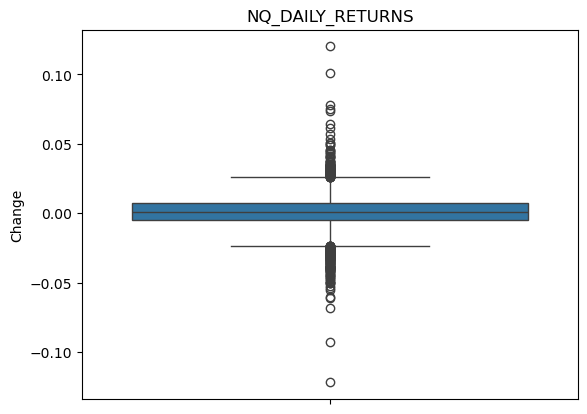

In [144]:
sns.boxplot(data=df.loc[df["market"] == 'Nasdaq100' , "Change"])
plt.title("NQ_DAILY_RETURNS")
plt.show()

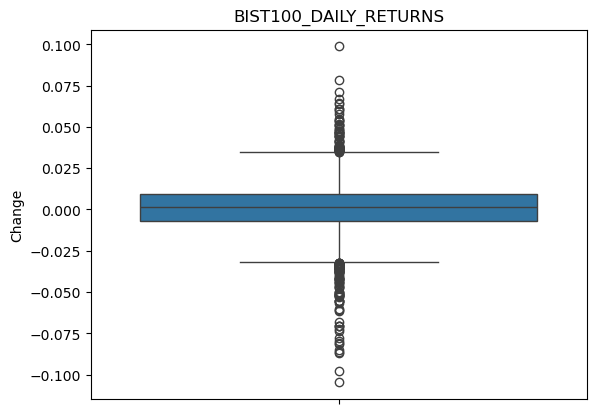

In [145]:
sns.boxplot(data=df.loc[(df["market"] == 'Bist100') & (df["Change"] > -0.2), "Change"])
plt.title("BIST100_DAILY_RETURNS")
plt.show()

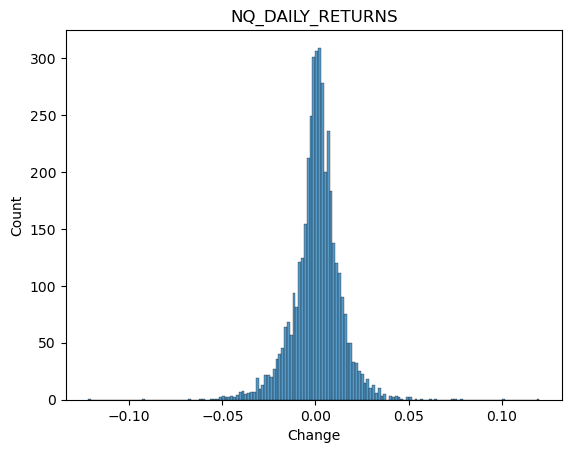

In [143]:
sns.histplot(data=df.loc[df["market"] == 'Nasdaq100' , "Change"])
plt.title("NQ_DAILY_RETURNS")
plt.show()

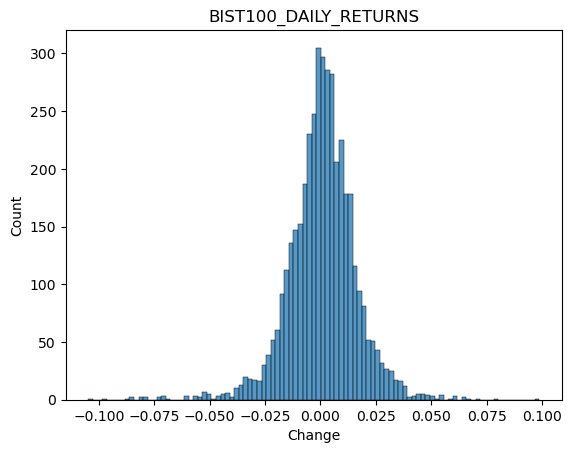

In [146]:
sns.histplot(data=df.loc[(df["market"] == 'Bist100') & (df["Change"] > -0.2), "Change"])
plt.title("BIST100_DAILY_RETURNS")
plt.show()